In [133]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


In [134]:
df = pd.read_csv('/content/Hostel.csv')
df.head()

,Unnamed: 0,hostel.name,City,price.from,Distance,summary.score,rating.band,atmosphere,cleanliness,facilities,location.y,security,staff,valueformoney,lon,lat
0,1,"""Bike & Bed"" CharinCo Hostel",Osaka,3300,2.9km from city centre,9.2,Superb,8.9,9.4,9.3,8.9,9.0,9.4,9.4,135.513767,34.682678
1,2,& And Hostel,Fukuoka-City,2600,0.7km from city centre,9.5,Superb,9.4,9.7,9.5,9.7,9.2,9.7,9.5,NaN,NaN
2,3,&And Hostel Akihabara,Tokyo,3600,7.8km from city centre,8.7,Fabulous,8.0,7.0,9.0,8.0,10.0,10.0,9.0,139.777472,35.697447
3,4,&And Hostel Ueno,Tokyo,2600,8.7km from city centre,7.4,Very Good,8.0,7.5,7.5,7.5,7.0,8.0,6.5,139.783667,35.712716
4,5,&And Hostel-Asakusa North-,Tokyo,1500,10.5km from city centre,9.4,Superb,9.5,9.5,9.0,9.0,9.5,10.0,9.5,139.798371,35.727898


In [135]:
df.tail()

,Unnamed: 0,hostel.name,City,price.from,Distance,summary.score,rating.band,atmosphere,cleanliness,facilities,location.y,security,staff,valueformoney,lon,lat
337,338,YADOYA Guesthouse Green,Tokyo,2300,2.6km from city centre,8.2,Fabulous,7.9,7.7,6.9,8.9,8.9,8.8,8.3,139.668125,35.702908
338,339,YADOYA Guesthouse Orange,Tokyo,2000,2.9km from city centre,8.9,Fabulous,8.6,9.0,7.8,9.4,9.0,9.2,9.4,139.667695,35.706513
339,340,YAWP! backpackers,Tokyo,2500,17.5km from city centre,9.3,Superb,9.5,9.3,9.4,8.5,9.5,9.2,9.6,139.869197,35.752885
340,341,You En Me House,Kyoto,2800,2.4km from city centre,8.0,Fabulous,7.3,8.0,6.7,8.0,8.7,10.0,7.3,135.749063,34.997376
341,342,Zabutton Hostel,Tokyo,2900,5.9km from city centre,8.6,Fabulous,8.1,8.5,7.8,9.0,8.9,9.5,8.5,139.742116,35.655470


In [136]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 342 entries, 0 to 341
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     342 non-null    int64  
 1   hostel.name    342 non-null    object 
 2   City           342 non-null    object 
 3   price.from     342 non-null    int64  
 4   Distance       342 non-null    object 
 5   summary.score  327 non-null    float64
 6   rating.band    327 non-null    object 
 7   atmosphere     327 non-null    float64
 8   cleanliness    327 non-null    float64
 9   facilities     327 non-null    float64
 10  location.y     327 non-null    float64
 11  security       327 non-null    float64
 12  staff          327 non-null    float64
 13  valueformoney  327 non-null    float64
 14  lon            298 non-null    float64
 15  lat            298 non-null    float64
dtypes: float64(10), int64(2), object(4)
memory usage: 42.9+ KB


In [137]:
df.shape

(342, 16)

In [138]:
df.columns

Index(['Unnamed: 0', 'hostel.name', 'City', 'price.from', 'Distance',
       'summary.score', 'rating.band', 'atmosphere', 'cleanliness',
       'facilities', 'location.y', 'security', 'staff', 'valueformoney', 'lon',
       'lat'],
      dtype='object')

In [139]:
df.isnull().sum()

,0
Unnamed: 0,0
hostel.name,0
City,0
price.from,0
Distance,0
summary.score,15
rating.band,15
atmosphere,15
cleanliness,15
facilities,15


In [140]:
df['rating.band'].nunique()

5

In [141]:
df['rating.band'].unique()

array(['Superb', 'Fabulous', 'Very Good', nan, 'Rating', 'Good'],
      dtype=object)

In [142]:
df['Unnamed: 0'].nunique()

342

In [143]:
df['Unnamed: 0'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [144]:
df['hostel.name'].nunique()

342

In [145]:
df['hostel.name'].unique()

array(['"Bike & Bed" CharinCo Hostel', '& And Hostel',
       '&And Hostel Akihabara', '&And Hostel Ueno',
       '&And Hostel-Asakusa North-', '1night1980hostel Tokyo',
       '328 Hostel & Lounge', '36Hostel', '3Q House - Asakusa Smile',
       'Ace Inn Shinjuku', 'Air Osaka Hostel', 'Aizuya Inn',
       'Akihabara Hotel 3000', 'Almond hostel & cafe Shibuya',
       'Anne Hostel Asakusabashi', 'Anne Hostel Yokozuna', 'Ark Hostel',
       'ARTnSHELTER', 'AS House (Asakusa Smile)',
       'Asakusa Hostel Toukaisou', 'Asakusa Ryokan Toukaisou',
       'Asakusahotel Wasou', 'Astro Station', 'B&S Eco Cube Shinsaibashi',
       "Backpackers Hostel K's House Hiroshima",
       "Backpackers Hostel K's House Kyoto",
       "Backpackers Hostel K's House Tokyo",
       'Backpackers Hotel Toyo Osaka', 'Backstage Osaka Hostel & Bar',
       'Beagle Tokyo Hostel & Apartments', 'Bed Stock',
       'Beehive Hostel Osaka', 'Bigtree Guesthouse', 'Bird Hostel',
       'bnb+ Ninja Dojo Ueno', 'bnb+Shinj

In [146]:
df['City'].nunique()

5

In [147]:
df['City'].unique()

array(['Osaka', 'Fukuoka-City', 'Tokyo', 'Hiroshima', 'Kyoto'],
      dtype=object)

In [148]:
df['price.from'].nunique()

42

In [149]:
df['price.from'].unique()

array([   3300,    2600,    3600,    1500,    2100,    2000,    2500,
          2200,    1600,    2900,    1800,    2700,    2400,    1300,
          3500,    3800,    4100,    4300,    6200,    6000,    3000,
          3100,    2800,    1000,    1700,    2300,    3200,    1900,
          4000,    1400,    3400,    4200,    1200,    3900,    6500,
          5500,    3700, 1003200,    7600,    6300,    5400,    5200])

In [150]:
df['Distance'].nunique()

119

In [151]:
df['Distance'].unique()

array(['2.9km from city centre', '0.7km from city centre',
       '7.8km from city centre', '8.7km from city centre',
       '10.5km from city centre', '9.4km from city centre',
       '16.5km from city centre', '1.6km from city centre',
       '10.2km from city centre', '3km from city centre',
       '9.7km from city centre', '10.6km from city centre',
       '8km from city centre', '2.2km from city centre',
       '8.9km from city centre', '9.5km from city centre',
       '1.9km from city centre', '10km from city centre',
       '9.3km from city centre', '9.9km from city centre',
       '3.8km from city centre', '4km from city centre',
       '2.4km from city centre', '9.2km from city centre',
       '6.5km from city centre', '4.5km from city centre',
       '16.1km from city centre', '1.1km from city centre',
       '3.4km from city centre', '36.6km from city centre',
       '1.3km from city centre', '5.9km from city centre',
       '0.9km from city centre', '9.6km from city centre'

In [152]:
df['summary.score'].nunique()

44

In [153]:
df['summary.score'].unique()

array([ 9.2,  9.5,  8.7,  7.4,  9.4,  7. ,  9.3,  nan,  7.7,  8.5, 10. ,
        9.1,  9. ,  8.3,  7.8,  8.9,  8.4,  8.6,  8.8,  9.6,  5.2,  5. ,
        8.2,  9.9,  6.9,  8. ,  8.1,  3.1,  9.7,  9.8,  7.1,  7.6,  7.5,
        4.9,  6.4,  6.6,  6.5,  6. ,  7.9,  5.1,  7.3,  6.3,  5.7,  6.2,
        6.8])

In [154]:
df['atmosphere'].nunique()

42

In [155]:
df['atmosphere'].unique()

array([ 8.9,  9.4,  8. ,  9.5,  5.5,  8.7,  8.8,  nan,  6.7,  8.1, 10. ,
        9.1,  8.2,  7.9,  7.1,  7.5,  9. ,  8.6,  9.3,  4. ,  2.7,  7.6,
        6. ,  6.5,  7.7,  7.2,  8.3,  2. ,  9.6,  7.8,  7.3,  9.8,  9.2,
        6.3,  8.4,  8.5,  9.7,  5.4,  7. ,  4.8,  7.4,  6.8,  5.3])

In [156]:
df['cleanliness'].nunique()

38

In [157]:
df['cleanliness'].unique()

array([ 9.4,  9.7,  7. ,  7.5,  9.5,  8. ,  9.9,  nan,  7.2,  9.1,  8.3,
       10. ,  9.2,  8.1,  6.2,  8.4,  9.3,  9. ,  8.2,  9.8,  3.3,  4. ,
        9.6,  8.7,  6.5,  8.9,  8.5,  2. ,  8.6,  6. ,  8.8,  7.1,  7.3,
        5.1,  7.7,  5.8,  6.4,  7.9,  6.7])

In [158]:
df['facilities'].nunique()

40

In [159]:
df['facilities'].unique()

array([ 9.3,  9.5,  9. ,  7.5,  6. ,  9.2,  nan,  6.8,  8.7,  8.4, 10. ,
        8.8,  8.9,  7.7,  7. ,  8.3,  8. ,  8.5,  8.1,  4. ,  3.3,  8.6,
        9.6,  7.3,  9.1,  9.8,  9.7,  2. ,  9.4,  7.9,  7.8,  7.4,  8.2,
        7.6,  9.9,  6.7,  5.3,  5.6,  5.7,  6.6,  6.9])

In [160]:
df['location.y'].nunique()

36

In [161]:
df['location.y'].unique()

array([ 8.9,  9.7,  8. ,  7.5,  9. ,  6. ,  9.1,  9.6,  nan,  8.5,  8.8,
        7.8, 10. ,  9.5,  9.2,  7.9,  9.4,  8.6,  8.7,  7.3,  9.3,  7. ,
        9.8,  8.3,  7.4,  4. ,  8.2,  8.1,  6.8,  7.6,  8.4,  6.7,  7.1,
        6.5,  2. ,  9.9,  5.4])

In [162]:
df['security'].nunique()

38

In [163]:
df['security'].unique()

array([ 9. ,  9.2, 10. ,  7. ,  9.5,  8.5,  9.3,  9.8,  nan,  7.8,  8.9,
        9.4,  9.1,  8.2,  8.8,  7.1,  8.6,  5.3,  9.6,  8. ,  7.7,  8.7,
        6. ,  7.5,  7.3,  6.9,  6.3,  9.9,  9.7,  8.3,  2. ,  5. ,  7.9,
        6.7,  8.4,  6.4,  4. ,  5.7,  7.4])

In [164]:
df['valueformoney'].nunique()

35

In [165]:
df['valueformoney'].unique()

array([ 9.4,  9.5,  9. ,  6.5,  8.9,  nan,  8.1, 10. ,  9.2,  8.3,  8.8,
        9.3,  9.1,  8.6,  6.7,  9.6,  8. ,  7.4,  8.7,  7. ,  8.2,  9.7,
        4. ,  9.8,  8.5,  7.3,  9.9,  7.5,  7.6,  6. ,  5.3,  6.6,  5.8,
        7.9,  8.4,  6.9])

In [166]:
df['lon'].nunique()

296

In [167]:
df['lon'].unique()

array([135.5137671,         nan, 139.7774724, 139.783667 , 139.7983712,
       139.7869499, 139.7454672, 139.7243036, 135.4769556, 139.800993 ,
       139.779382 , 139.6875352, 139.7893595, 139.7967977, 103.8731349,
       139.742108 , 139.800616 , 139.79081  , 139.7966971, 139.7036929,
       135.4991771, 132.473831 , 135.764916 , 139.792253 , 135.5041024,
       135.513299 , 139.7410778, 135.508387 , 135.3233376, 135.7587254,
       135.506891 , 135.7727965, 139.7949806, 130.3979662, 139.7085388,
       139.79322  , 135.497847 , 139.81198  , 135.7535562, 139.7707637,
       135.761618 , 139.7376971, 139.770129 , 135.8007905, 139.781352 ,
       135.508221 , 135.7676061, 130.4032209, 135.4971528, 135.5052683,
       135.755182 , 135.4886189, 139.8638707, 139.791216 , 139.795301 ,
       135.535271 , 139.79148  , 135.7718   , 130.428142 , 130.4097719,
       135.503623 , 135.7795363, 135.6505111, 135.7722097, 135.775803 ,
       139.7182582, 135.764823 , 139.780326 , 139.783943 , 135.7

In [168]:
df['staff'].nunique()

30

In [169]:
df['staff'].unique()

array([ 9.4,  9.7, 10. ,  8. ,  8.5,  9.8,  nan,  9.1,  9.5,  9.3,  9.2,
        9. ,  8.9,  8.6,  9.6,  4.7,  5.3,  6.5,  8.8,  2. ,  8.7,  7.3,
        9.9,  6.9,  7. ,  7.4,  6.3,  6. ,  8.4,  6.8,  7.1])

In [170]:
df['lat'].nunique()

296

In [171]:
df['lat'].unique()

array([34.682678 ,        nan, 35.6974473, 35.712716 , 35.7278979,
       35.724384 , 35.5480439, 35.6925119, 34.6222596, 35.727547 ,
       35.6974904, 35.6700092, 35.6989448, 35.6954897,  1.3108203,
       35.604242 , 35.707363 , 35.713177 , 35.7118769, 35.7143962,
       34.6707458, 34.392506 , 34.989791 , 35.705066 , 34.6483651,
       34.6670083, 35.5504924, 34.676892 , 34.4119443, 35.0175416,
       34.621308 , 35.0041178, 35.7107965, 33.5909933, 35.7310808,
       35.712108 , 34.6707858, 35.6981223, 35.0112333, 35.6895954,
       35.003533 , 35.6738463, 35.709199 , 34.8876476, 35.691571 ,
       34.6644243, 35.0053862, 33.5978245, 34.6550004, 34.6678045,
       35.0052769, 34.7001589, 35.7129526, 35.7782   , 35.7121845,
       34.6757318, 35.72369  , 35.001371 , 33.584119 , 33.5926482,
       34.656784 , 35.0014418, 34.815565 , 34.9954879, 34.998209 ,
       35.7346756, 35.004678 , 35.696562 , 35.690286 , 35.0147747,
       34.405665 , 35.7128268, 35.009131 , 34.9915805, 35.0096

In [172]:
df.isnull().sum()

,0
Unnamed: 0,0
hostel.name,0
City,0
price.from,0
Distance,0
summary.score,15
rating.band,15
atmosphere,15
cleanliness,15
facilities,15


# Null value replacing

In [173]:
df['summary.score'].fillna(df['summary.score'].mean(),inplace=True)

/tmp/ipykernel_512/1323486650.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['summary.score'].fillna(df['summary.score'].mean(),inplace=True)


In [174]:
df['atmosphere'].fillna(df['atmosphere'].mean(),inplace=True)

/tmp/ipykernel_512/2598561847.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['atmosphere'].fillna(df['atmosphere'].mean(),inplace=True)


In [175]:
df['cleanliness'].fillna(df['cleanliness'].mean(),inplace=True)

/tmp/ipykernel_512/3043748235.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['cleanliness'].fillna(df['cleanliness'].mean(),inplace=True)


In [176]:
df['facilities'].fillna(df['facilities'].mean(),inplace=True)

/tmp/ipykernel_512/2767443193.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['facilities'].fillna(df['facilities'].mean(),inplace=True)


In [177]:
df['location.y'].fillna(df['location.y'].mean(),inplace=True)

/tmp/ipykernel_512/2367851035.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['location.y'].fillna(df['location.y'].mean(),inplace=True)


In [178]:
df['security'].fillna(df['security'].mean(),inplace=True)

/tmp/ipykernel_512/3759503210.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['security'].fillna(df['security'].mean(),inplace=True)


In [179]:
df['staff'].fillna(df['staff'].mean(),inplace=True)

/tmp/ipykernel_512/3785720383.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['staff'].fillna(df['staff'].mean(),inplace=True)


In [180]:
df['lat'].fillna(df['lat'].mean(),inplace=True)

/tmp/ipykernel_512/1929265479.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['lat'].fillna(df['lat'].mean(),inplace=True)


In [181]:
df['lon'].fillna(df['lon'].mean(),inplace=True)

/tmp/ipykernel_512/2150270869.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['lon'].fillna(df['lon'].mean(),inplace=True)


In [182]:
df.isnull().sum()

,0
Unnamed: 0,0
hostel.name,0
City,0
price.from,0
Distance,0
summary.score,0
rating.band,15
atmosphere,0
cleanliness,0
facilities,0


In [183]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 342 entries, 0 to 341
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     342 non-null    int64  
 1   hostel.name    342 non-null    object 
 2   City           342 non-null    object 
 3   price.from     342 non-null    int64  
 4   Distance       342 non-null    object 
 5   summary.score  342 non-null    float64
 6   rating.band    327 non-null    object 
 7   atmosphere     342 non-null    float64
 8   cleanliness    342 non-null    float64
 9   facilities     342 non-null    float64
 10  location.y     342 non-null    float64
 11  security       342 non-null    float64
 12  staff          342 non-null    float64
 13  valueformoney  327 non-null    float64
 14  lon            342 non-null    float64
 15  lat            342 non-null    float64
dtypes: float64(10), int64(2), object(4)
memory usage: 42.9+ KB


In [184]:
df['rating.band'].fillna('unknown',inplace=True)

/tmp/ipykernel_512/3353074350.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['rating.band'].fillna('unknown',inplace=True)


In [185]:
df['valueformoney'].fillna(df['valueformoney'].mean(),inplace=True)

/tmp/ipykernel_512/3832977476.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['valueformoney'].fillna(df['valueformoney'].mean(),inplace=True)


In [186]:
df.isnull().sum()

,0
Unnamed: 0,0
hostel.name,0
City,0
price.from,0
Distance,0
summary.score,0
rating.band,0
atmosphere,0
cleanliness,0
facilities,0


In [187]:
df.head()

,Unnamed: 0,hostel.name,City,price.from,Distance,summary.score,rating.band,atmosphere,cleanliness,facilities,location.y,security,staff,valueformoney,lon,lat
0,1,"""Bike & Bed"" CharinCo Hostel",Osaka,3300,2.9km from city centre,9.2,Superb,8.9,9.4,9.3,8.9,9.0,9.4,9.4,135.513767,34.682678
1,2,& And Hostel,Fukuoka-City,2600,0.7km from city centre,9.5,Superb,9.4,9.7,9.5,9.7,9.2,9.7,9.5,136.756376,34.976583
2,3,&And Hostel Akihabara,Tokyo,3600,7.8km from city centre,8.7,Fabulous,8.0,7.0,9.0,8.0,10.0,10.0,9.0,139.777472,35.697447
3,4,&And Hostel Ueno,Tokyo,2600,8.7km from city centre,7.4,Very Good,8.0,7.5,7.5,7.5,7.0,8.0,6.5,139.783667,35.712716
4,5,&And Hostel-Asakusa North-,Tokyo,1500,10.5km from city centre,9.4,Superb,9.5,9.5,9.0,9.0,9.5,10.0,9.5,139.798371,35.727898


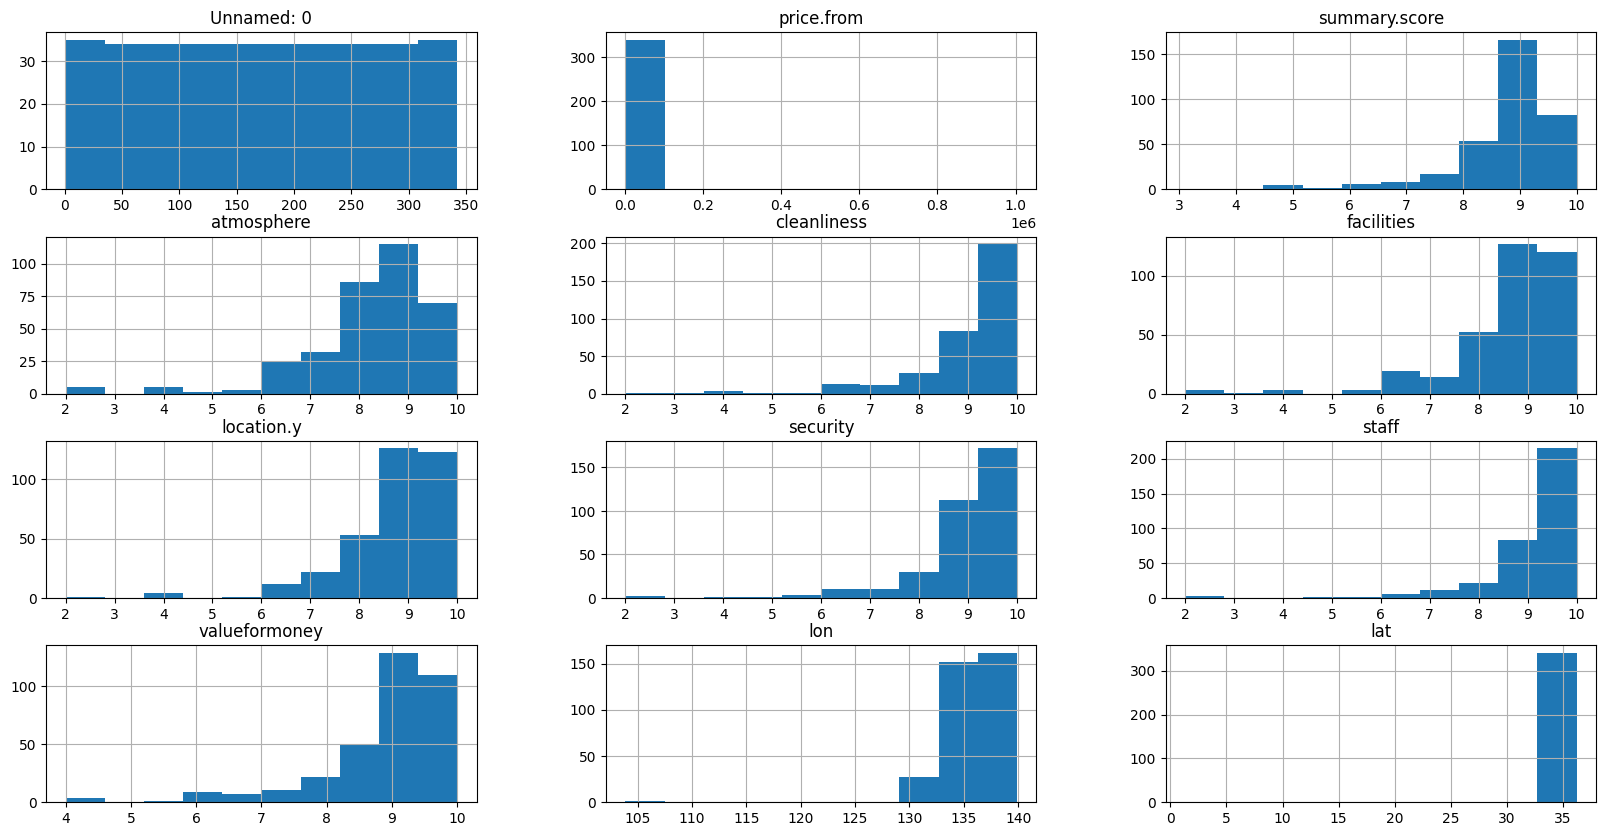

In [188]:
df.hist(figsize=(20,10))
plt.show()

In [189]:
df.sample(3)

,Unnamed: 0,hostel.name,City,price.from,Distance,summary.score,rating.band,atmosphere,cleanliness,facilities,location.y,security,staff,valueformoney,lon,lat
187,188,J-Hoppers Hiroshima Guesthouse,Hiroshima,2300,1.1km from city centre,9.1,Superb,8.5,9.3,9.0,9.3,9.3,9.4,9.2,132.447244,34.393021
235,236,Nihonbashi Muromachi BAY HOTEL,Tokyo,4000,7.6km from city centre,9.2,Superb,9.0,9.7,8.7,8.3,10.0,9.3,9.3,139.775679,35.687297
282,283,Sakura Hotel Ikebukuro,Tokyo,2300,5.1km from city centre,8.3,Fabulous,7.3,8.2,7.9,9.0,7.8,9.1,8.8,139.708803,35.733614


In [190]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 342 entries, 0 to 341
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     342 non-null    int64  
 1   hostel.name    342 non-null    object 
 2   City           342 non-null    object 
 3   price.from     342 non-null    int64  
 4   Distance       342 non-null    object 
 5   summary.score  342 non-null    float64
 6   rating.band    342 non-null    object 
 7   atmosphere     342 non-null    float64
 8   cleanliness    342 non-null    float64
 9   facilities     342 non-null    float64
 10  location.y     342 non-null    float64
 11  security       342 non-null    float64
 12  staff          342 non-null    float64
 13  valueformoney  342 non-null    float64
 14  lon            342 non-null    float64
 15  lat            342 non-null    float64
dtypes: float64(10), int64(2), object(4)
memory usage: 42.9+ KB


In [191]:
df.describe()

,Unnamed: 0,price.from,summary.score,atmosphere,cleanliness,facilities,location.y,security,staff,valueformoney,lon,lat
count,342.000000,3.420000e+02,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000
mean,171.500000,8.388012e+03,8.782569,8.238838,9.011927,8.597554,8.694801,8.947401,9.133333,8.848318,136.756376,34.976583
std,98.871128,7.641527e+04,0.939537,1.351264,1.188734,1.256768,1.078178,1.089560,1.062348,1.024504,3.034946,1.904680
min,1.000000,1.000000e+03,3.100000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,4.000000,103.873135,1.310820
25%,86.250000,2.000000e+03,8.600000,7.900000,8.900000,8.100000,8.125000,8.800000,9.000000,8.600000,135.507309,34.674133
50%,171.500000,2.500000e+03,9.000000,8.500000,9.300000,8.900000,8.950000,9.200000,9.300000,9.000000,135.775973,34.988713
75%,256.750000,2.900000e+03,9.300000,9.000000,9.800000,9.300000,9.400000,9.600000,9.800000,9.500000,139.741850,35.692624
max,342.000000,1.003200e+06,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,139.877880,36.204824


In [192]:
df.head()

,Unnamed: 0,hostel.name,City,price.from,Distance,summary.score,rating.band,atmosphere,cleanliness,facilities,location.y,security,staff,valueformoney,lon,lat
0,1,"""Bike & Bed"" CharinCo Hostel",Osaka,3300,2.9km from city centre,9.2,Superb,8.9,9.4,9.3,8.9,9.0,9.4,9.4,135.513767,34.682678
1,2,& And Hostel,Fukuoka-City,2600,0.7km from city centre,9.5,Superb,9.4,9.7,9.5,9.7,9.2,9.7,9.5,136.756376,34.976583
2,3,&And Hostel Akihabara,Tokyo,3600,7.8km from city centre,8.7,Fabulous,8.0,7.0,9.0,8.0,10.0,10.0,9.0,139.777472,35.697447
3,4,&And Hostel Ueno,Tokyo,2600,8.7km from city centre,7.4,Very Good,8.0,7.5,7.5,7.5,7.0,8.0,6.5,139.783667,35.712716
4,5,&And Hostel-Asakusa North-,Tokyo,1500,10.5km from city centre,9.4,Superb,9.5,9.5,9.0,9.0,9.5,10.0,9.5,139.798371,35.727898


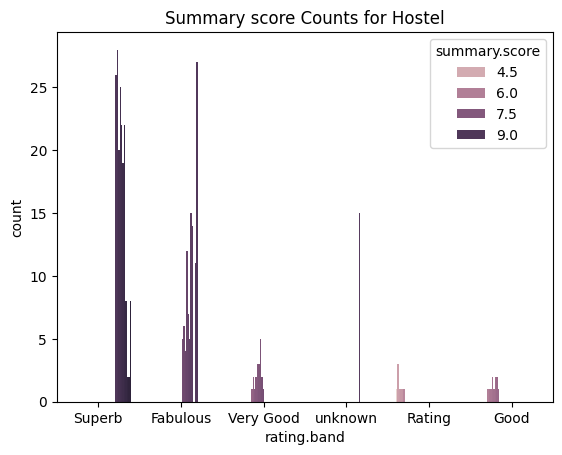

In [193]:
sns.countplot(x='rating.band' , hue='summary.score',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

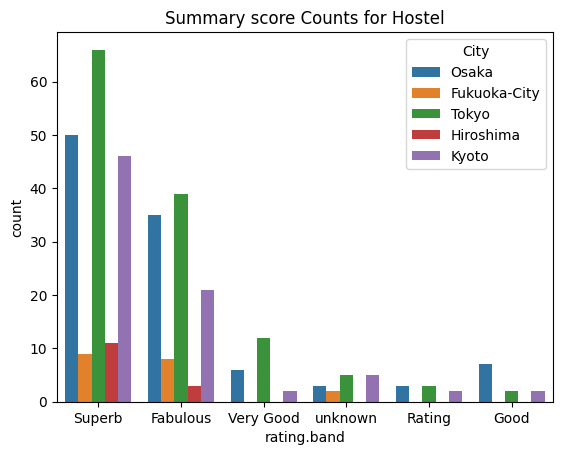

In [194]:
sns.countplot(x='rating.band' , hue='City',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

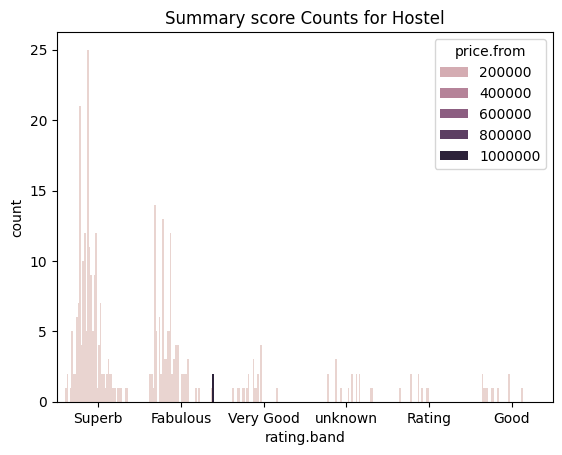

In [195]:
sns.countplot(x='rating.band' , hue='price.from',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

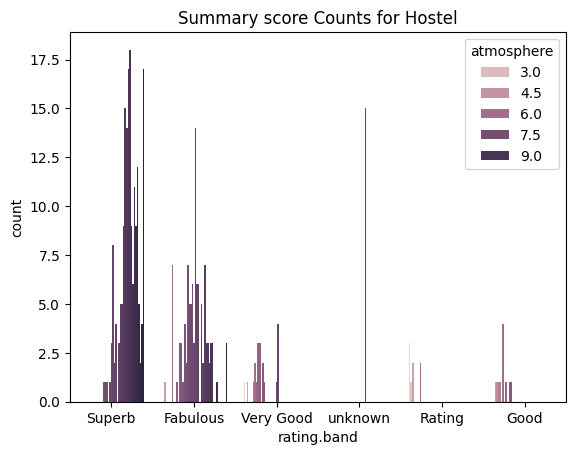

In [196]:
sns.countplot(x='rating.band' , hue='atmosphere',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

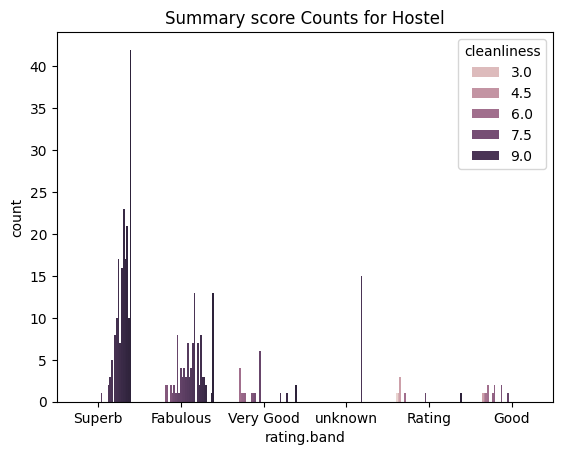

In [197]:
sns.countplot(x='rating.band' , hue='cleanliness',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

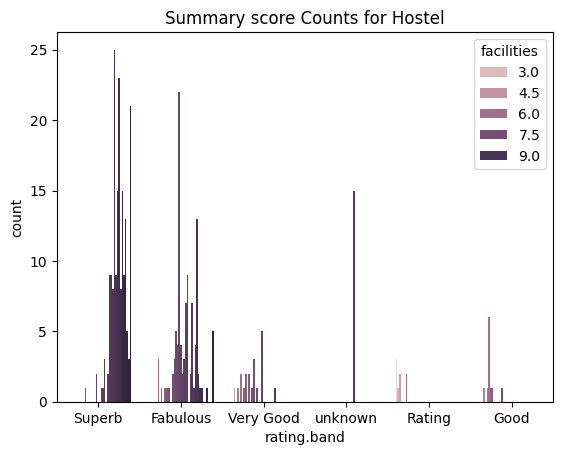

In [198]:
sns.countplot(x='rating.band' , hue='facilities',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

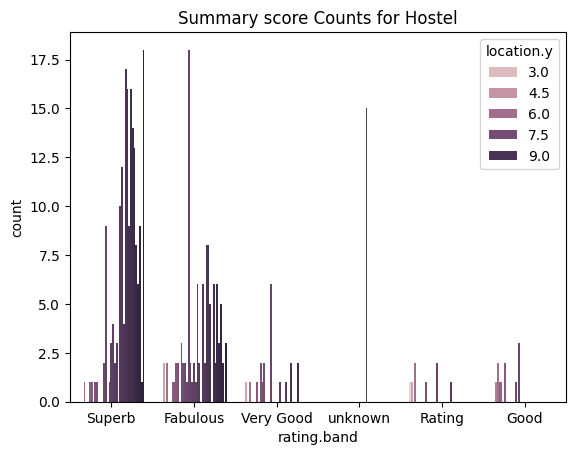

In [199]:
sns.countplot(x='rating.band' , hue='location.y',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

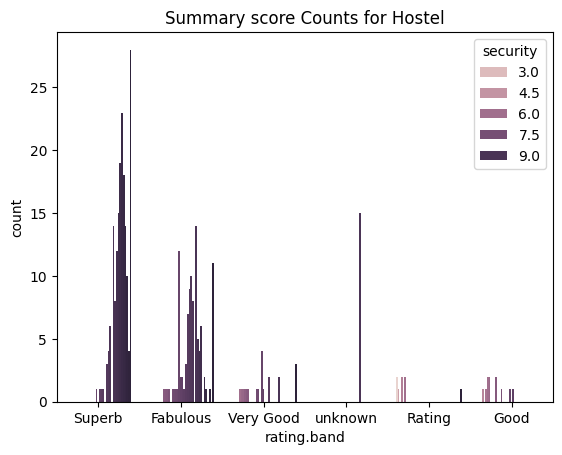

In [200]:
sns.countplot(x='rating.band' , hue='security',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

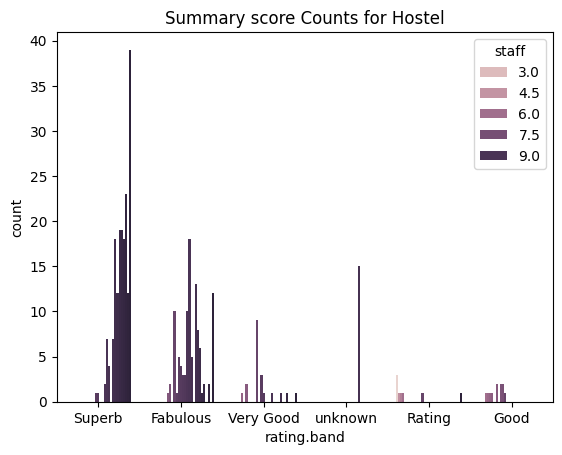

In [201]:
sns.countplot(x='rating.band' , hue='staff',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

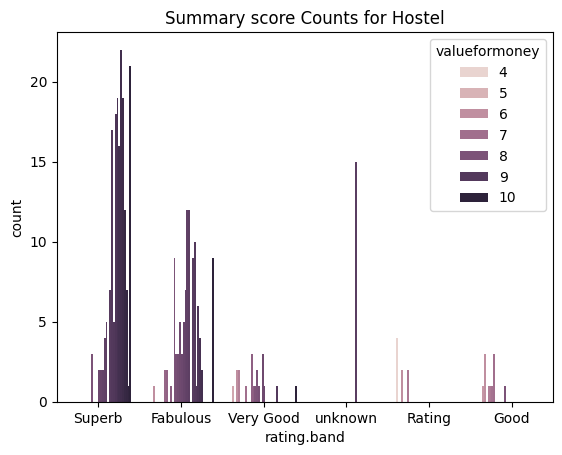

In [202]:
sns.countplot(x='rating.band' , hue='valueformoney',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

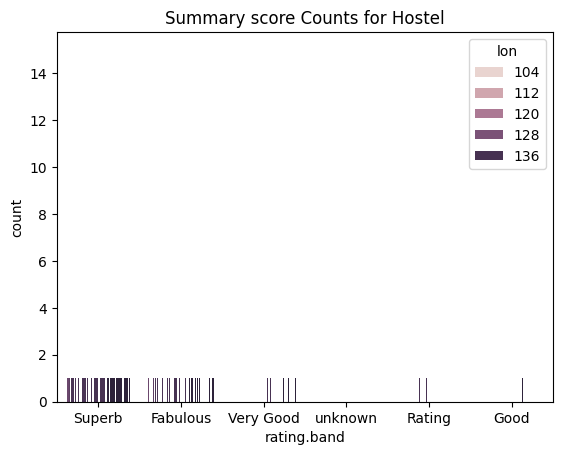

In [203]:
sns.countplot(x='rating.band' , hue='lon',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()

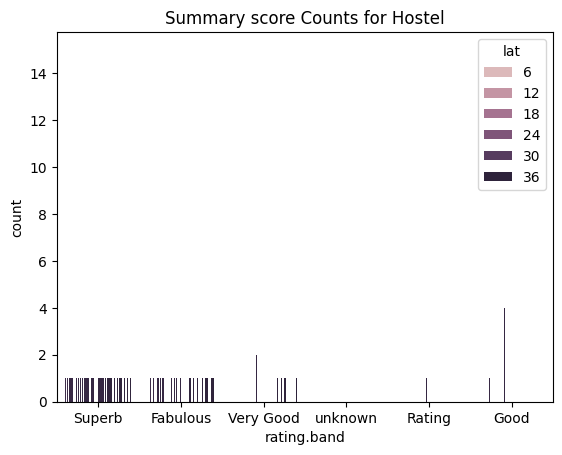

In [204]:
sns.countplot(x='rating.band' , hue='lat',data=df)
plt.title('Summary score Counts for Hostel')
plt.show()